Today's topics:
* the influence of one reading on least squares
* mean absolute error as an objective for `minimize`
* fitting a subgroup

# A catalyst screening campaign

In Lecture 22, we fitted models by minimizing squared residuals.
Today we will compare that objective with mean absolute error.

Our data are catalyst formulations tested for how much CO₂ they convert.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/5/5a/Heterrogenous_catalysis_across_scales.png/960px-Heterrogenous_catalysis_across_scales.png" alt="A rendered illustration of a heterogeneous catalyst at five length scales: an atomic surface with active sites, metal nanoparticles on a porous support, a cylindrical catalyst pellet, a reactor bed filled with pellets, and an industrial reactor, with a chart below of processes by time and size" width=520/>

*Image by Edvin Fako, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Heterrogenous_catalysis_across_scales.png).*

Above: A supported metal catalyst from the nanometer to the reactor scale.

Small metal particles sit on a porous support. The support is formed into pellets.
The pellets fill the reactor bed, and the gas flows through it.

The data are from the [Swiss Cat+ CO₂ hydrogenation campaign](https://zenodo.org/records/8314734)
(Ramirez et al., CC BY 4.0). The table has 143 formulations tested at 275 °C.
`Total Metal Loading [wt%]` is the mass percentage of added metals in a catalyst.
`CO2 Conversion (%)` is the percentage of incoming CO₂ that reacted.

This campaign began with a mixed-support screening batch.
Later batches were selected by an optimizer and used ZrO₂ support.

Let's load the table and plot conversion against metal loading:

143


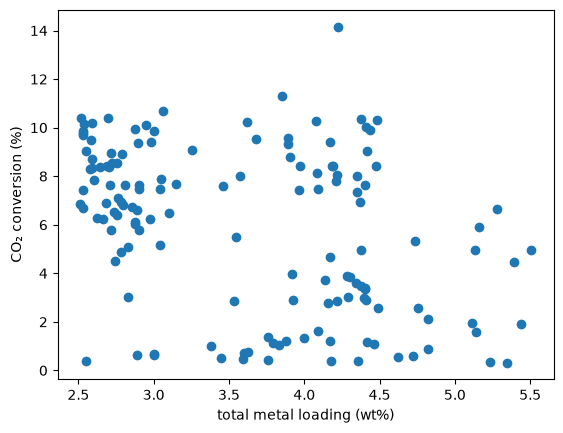

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

data = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/catalysis_swisscat_275c.csv')
loading = data['Total Metal Loading [wt%]'].to_numpy()
conversion = data['CO2 Conversion (%)'].to_numpy()
print(len(data))

fig, ax = plt.subplots()
ax.plot(loading, conversion, 'o')
ax.set_xlabel('total metal loading (wt%)')
ax.set_ylabel('CO₂ conversion (%)')
plt.show()

The cloud is broad, so a line will be a rough summary.
Let's fit the recorded table:

In [2]:
fit_clean = stats.linregress(loading, conversion)
pred_clean = fit_clean.slope * loading + fit_clean.intercept

# slope: conversion percentage points per wt% loading
print(fit_clean.slope, fit_clean.rvalue**2)

-1.5156314862123175 0.14694348986463707


# Influence of one reading

The largest recorded conversion is about 14.16%.
Let's multiply it by ten in a copy of the array.

The resulting 141.58% exceeds the physical limit of 100%.

In [3]:
bad_index = np.argmax(conversion)  # row with the largest conversion
conversion_typo = conversion.copy()  # a copy, so conversion stays unchanged
conversion_typo[bad_index] = 10 * conversion_typo[bad_index]  # planted typo
print(conversion[bad_index], conversion_typo[bad_index])

14.15811003 141.5811003


Let's fit both arrays with least squares:

In [4]:
fit_typo = stats.linregress(loading, conversion_typo)
print(fit_clean.slope, fit_typo.slope)

-1.5156314862123175 -0.7690190130700779


The one wrong value moves the slope from about -1.52 to -0.77.
How much of the typo fit's squared error comes from that one value?

In [5]:
pred_typo = fit_typo.slope * loading + fit_typo.intercept
residuals_typo = conversion_typo - pred_typo
squared_typo = residuals_typo**2
share_typo = squared_typo[bad_index] / np.sum(squared_typo)
print(share_typo)

0.9260782657446746


The planted value supplies a fraction 0.93, or about 93%, of the typo fit's squared error.
This generic sketch shows how one high reading changes a fit:

A residual of size $r$ adds $r^2$ to the sum of squares.
A miss ten times larger adds 100 times as much. Its absolute value grows only ten times.

We can instead minimize the average absolute size of the residuals:

# MAE as an objective

In Lecture 13, we calculated MAE after fitting.
Now let's use it as the objective for `minimize`:

In [6]:
def mae_line(params):
    m, b = params  # slope, intercept
    # conversion_typo comes from the notebook, not from params
    residuals = conversion_typo - (m * loading + b)
    return np.mean(np.abs(residuals))

> Recipe: for an absolute-value objective, use `method='Nelder-Mead'`.
> The default solver reports `success = False` with a precision-loss warning here.
> An absolute value has a sharp corner, and Nelder-Mead does not need derivatives.

Start both parameters at 1:

In [7]:
res_mae = optimize.minimize(mae_line, [1, 1], method='Nelder-Mead')
m_mae, b_mae = res_mae.x
print(m_mae, b_mae)
print(res_mae.fun, res_mae.success)

-2.362598088718992 14.030558785046555
3.3878981127601735 True


Least squares and MAE summarize this cloud differently.
Compare each with its own fit to the recorded table.

Let's plot both typo fits alongside the recorded-table least-squares line:

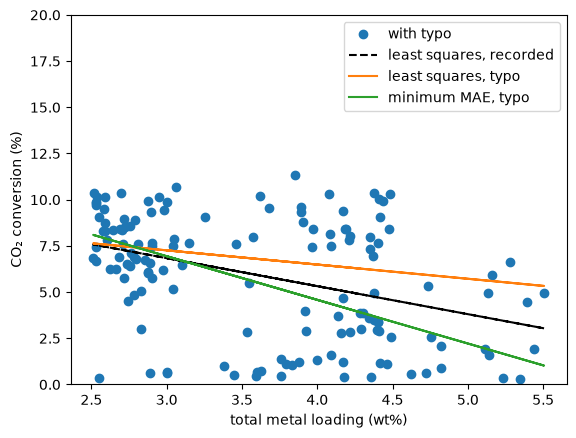

In [8]:
pred_mae = m_mae * loading + b_mae

fig, ax = plt.subplots()
ax.plot(loading, conversion_typo, 'o', label='with typo')
ax.plot(loading, pred_clean, 'k--', label='least squares, recorded')
ax.plot(loading, pred_typo, '-', label='least squares, typo')
ax.plot(loading, pred_mae, '-', label='minimum MAE, typo')
ax.set_xlabel('total metal loading (wt%)')
ax.set_ylabel('CO₂ conversion (%)')
ax.set_ylim(0, 20)  # the typo point is above this view
ax.legend()
plt.show()

Let's increase the error and compare how far each fitted slope moves.

### [Check your understanding]

Compare the two fits as one response error grows. Start with:

```
multipliers = [1, 2, 5, 10]
for multiplier in multipliers:
    conversion_typo = conversion.copy()  # mae_line reads this name
```

1. Inside the loop, multiply the value at `bad_index` by `multiplier`.
   Fit with least squares and with `minimize`, then print both slopes.
   Use `method='Nelder-Mead'` and start at `[1, 1]`.
2. Compare each slope with its value at multiplier 1. Which changes more?

Check: the slopes are -1.52 and -2.36 at multiplier 1,
and -0.77 and -2.36 at multiplier 10.

**Optional challenge:** how could you catch the 141.58% value before fitting?

## Drag the bad point

Run the cell once to activate the slider, then drag the bad reading from 0% to 300%.
Readings above 100% are impossible; here they test the fits.

The left panel shows the whole range. The right panel zooms in on the lines.
Watch how far each line moves, and how fast each score grows, as the reading gets farther from the others.

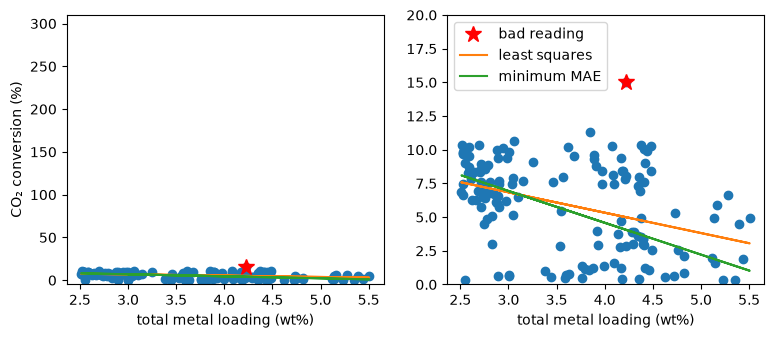

-1.5106985808450561 -2.362598088718992
9.566222332574965 2.502715593179753


In [9]:
# @title Drag the bad point {run:"auto"}
bad_value = 15 # @param {type:"slider", min:0, max:300, step:5}

conversion_typo = conversion.copy()  # mae_line reads this name
conversion_typo[bad_index] = bad_value

fit_bad = stats.linregress(loading, conversion_typo)
res_bad = optimize.minimize(mae_line, [1, 1], method='Nelder-Mead')
pred_bad_ls = fit_bad.slope * loading + fit_bad.intercept
pred_bad_mae = res_bad.x[0] * loading + res_bad.x[1]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax in axes:  # the same drawing on both panels
    ax.plot(loading, conversion_typo, 'o')
    ax.plot(loading[bad_index], bad_value, 'r*', markersize=12, label='bad reading')
    ax.plot(loading, pred_bad_ls, '-', label='least squares')
    ax.plot(loading, pred_bad_mae, '-', label='minimum MAE')
    ax.set_xlabel('total metal loading (wt%)')
axes[0].set_ylabel('CO₂ conversion (%)')
axes[0].set_ylim(-5, 310)  # the whole slider range
axes[1].set_ylim(0, 20)    # zoom on the lines
axes[1].legend(loc='upper left')
plt.show()
print(fit_bad.slope, res_bad.x[0])

mse_bad = np.mean((conversion_typo - pred_bad_ls)**2)
print(mse_bad, res_bad.fun)  # least-squares MSE, minimum MAE

# Fitting a subgroup

Now return to the recorded table. `Generation` records the campaign batch.
Generation 1 was the screening batch; the later generations were optimizer-selected.

Let's color those two groups and draw the pooled clean-data line:

24 119


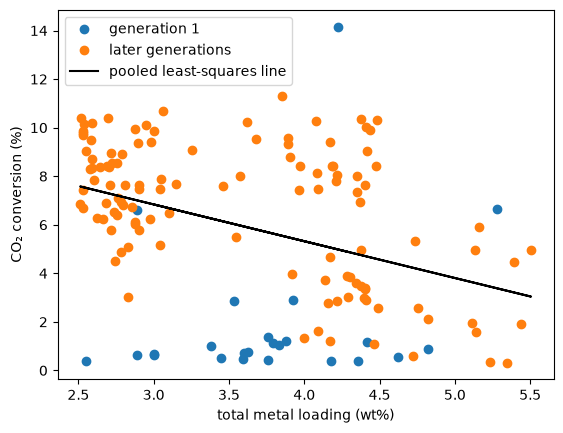

In [10]:
first = (data['Generation'] == '1').to_numpy()  # True on screening-batch rows
print(np.sum(first), np.sum(~first))

fig, ax = plt.subplots()
ax.plot(loading[first], conversion[first], 'o', label='generation 1')
ax.plot(loading[~first], conversion[~first], 'o', label='later generations')
ax.plot(loading, pred_clean, 'k-', label='pooled least-squares line')
ax.set_xlabel('total metal loading (wt%)')
ax.set_ylabel('CO₂ conversion (%)')
ax.legend()
plt.show()

The first batch is mostly below the pooled line.
Let's compare the median residual in each group, screening batch first:

In [11]:
residuals_clean = conversion - pred_clean
print(np.median(residuals_clean[first]))
print(np.median(residuals_clean[~first]))

-4.525042835989657
0.8598147971885766


These low rows are real experiments.
The two groups differ in both support and selection, so the gap does not isolate a support effect.

For a report about the screening batch, we would analyze that batch separately.

### [Check your understanding]

1. Use the `first` mask to fit a line to **Generation 1 only**
   with `stats.linregress`. That mask selects 24 of the 143 formulations.
2. Print its slope and R². Check: about +1.06 percentage points per wt% and R² about 0.05.
3. Compare its slope with the pooled line's -1.52. Does either line show
   that adding metal causes conversion to change? Why not?

**Optional challenge:** explain why a first-batch row below the pooled line
is not automatically a recording error.

# Conversion and selectivity

On the recorded table, which formulation lies farthest from the fitted line?
Let's inspect its record:

In [12]:
far_index = np.argmax(np.abs(residuals_clean))  # row with the largest miss
print(far_index, residuals_clean[far_index])

columns = ['Generation', 'Support', 'CO2 Conversion (%)',
           'Co Loading [wt%]', 'MeOH Selectivity (%)',
           'CH4 Selectivity(%)']
print(data.loc[far_index, columns])

10 9.17370639062924
Generation                      1
Support                      ZrO2
CO2 Conversion (%)       14.15811
Co Loading [wt%]         3.053739
MeOH Selectivity (%)     0.542407
CH4 Selectivity(%)      74.128775
Name: 10, dtype: object


**Conversion** says how much CO₂ reacted. **Selectivity** says what the reacted carbon became.

This formulation converted 14.16% of the feed, the most in this table.
Only 0.54% of the reacted carbon became methanol, and 74.13% became methane.

Compare it with the campaign's typical methanol selectivity:

In [13]:
methanol_selectivity = data['MeOH Selectivity (%)'].to_numpy()
print(np.median(methanol_selectivity))

34.83108881


Would you choose this formulation for methanol production?
Would you discard its measurement? Discuss with a neighbor.

The percentage of feed converted to methanol is
conversion × methanol selectivity / 100.
Let's compare the best methanol result with the highest-conversion result:

In [14]:
methanol_from_feed = conversion * methanol_selectivity / 100
best_methanol_index = np.argmax(methanol_from_feed)
print(far_index, methanol_from_feed[far_index])
print(best_methanol_index, methanol_from_feed[best_methanol_index])

10 0.07679464641353924
102 4.318994803524785


Row 102 converts 4.32% of the feed to methanol, versus 0.08% for the
highest-conversion formulation. We keep that formulation's checked record.

# Summary

* An MAE objective returns the mean absolute residual for trial model parameters.
* Absolute error grows linearly with residual size; squared error grows quadratically.
* `minimize` can fit the same model using different objective functions.

## Further reading

* [`scipy.optimize.minimize` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)
* Kong, Siauw, and Bayen, *Python Programming and Numerical Methods*, [Chapter 16, "Least Squares Regression"](https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter16.00-Least-Squares-Regression.html), for the least-squares objective that MAE replaces